# 🏠 Predictive Insight Engine

### Supervised Learning — Regression Analysis

**Project:** Predictive Insight Engine  
**Dataset:** Real Estate House Price Dataset  
**Objective:** Predict house prices using supervised learning regression techniques.

---

### Project Overview

In this project, I will build and evaluate different regression models to predict house prices.

I will begin with Simple Linear Regression and then move towards Multiple Linear Regression and Polynomial Regression. I will also implement Batch Gradient Descent, Stochastic Gradient Descent, and Mini-Batch Gradient Descent from scratch.

Finally, I will compare the models and study concepts such as model performance, overfitting, underfitting, bias, and variance.

# 🧠 Part A: Conceptual Understanding

Before working with the dataset, I will briefly understand the main supervised learning concepts used in this project.

## 1. What are Supervised Learning Algorithms?

Supervised learning is a type of machine learning where a model learns from data that already contains the correct answers, called target values. The model learns the relationship between input features and the target so that it can make predictions for new data.

## 2. Regression Algorithms vs Classification Algorithms

Regression algorithms are used when the target is a continuous numerical value, such as predicting the price of a house. Classification algorithms are used when the target belongs to a category, such as predicting whether a house is expensive or affordable.

## 3. Explain Simple Linear Regression

Simple Linear Regression uses one independent variable to predict a dependent variable. It tries to find the best straight line between the input and target using the equation:

**y = mx + c**

where `m` is the slope and `c` is the intercept.

## 4. Assumptions of Linear Regression

The main assumptions are linearity, independence of observations, constant variance of errors, and approximately normally distributed residuals. These assumptions help the model produce reliable and meaningful predictions.

## 5. What is Bias–Variance Trade-Off?

Bias is the error caused when a model is too simple to capture the important patterns in the data. Variance is the error caused when a model becomes too sensitive to the training data. A good model tries to balance both bias and variance.

## 6. Explain Overfitting and Underfitting

Overfitting happens when a model learns the training data too closely and performs poorly on new data. Underfitting happens when a model is too simple to learn the important patterns in the data, resulting in poor performance on both training and testing data.

# 🧪 Part B: Dataset Understanding & Preparation

Now I will work with the real estate dataset provided for this project.

The goal is to understand the dataset first before building any machine learning model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import time

## Loading the Dataset

The dataset contains information about different houses and their prices.

For this project, I will use the five features specified in the project brief:

- House Area
- Number of Bedrooms
- Number of Bathrooms
- Location Score
- Age of Property

The target variable will be the House Price.

In [2]:
df = pd.read_excel("RealEstate_HousePrice_Dataset_4200.xlsx")

df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [3]:
df.shape

(4200, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


## Selecting the Relevant Features

The original dataset contains some additional information, but the project brief specifically identifies the following features for this project.

I will therefore use only these features for the regression models:

- `area_sqft`
- `bedrooms`
- `bathrooms`
- `location_score`
- `age_years`

The target variable is:

- `house_price_inr`

In [5]:
features = [
    'area_sqft',
    'bedrooms',
    'bathrooms',
    'location_score',
    'age_years'
]

target = 'house_price_inr'

X = df[features]
y = df[target]

X.head()

,area_sqft,bedrooms,bathrooms,location_score,age_years
0,1973,5,4,7.6,23
1,1560,3,3,6.3,13
2,2071,4,3,5.8,9
3,2640,5,3,7.7,12
4,1498,3,3,3.8,15


## 7. Identify Independent and Dependent Variables

The independent variables are the house features used to make predictions:

- House Area
- Number of Bedrooms
- Number of Bathrooms
- Location Score
- Age of Property

The dependent variable is **House Price**, because this is the value that the model is trying to predict.

## 8. Visualizing Relationships Between Features and House Price

Before building the models, I will look at how each feature is related to the house price.

These plots will help me understand whether there appears to be a relationship between the features and the target variable.

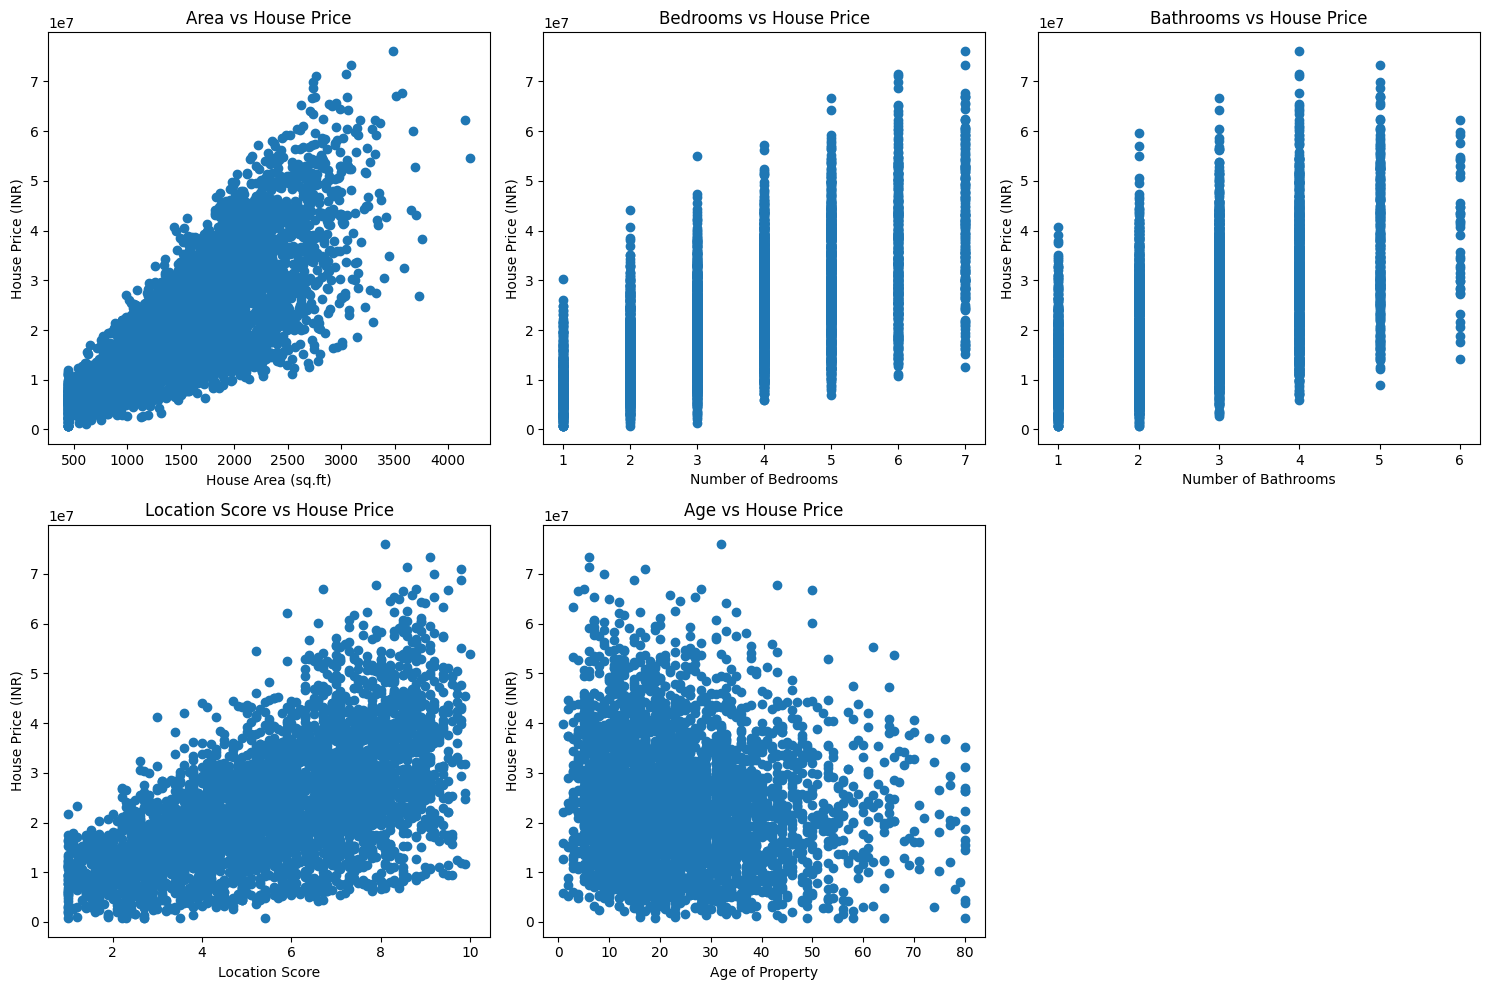

In [6]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.scatter(df['area_sqft'], df['house_price_inr'])
plt.xlabel('House Area (sq.ft)')
plt.ylabel('House Price (INR)')
plt.title('Area vs House Price')

plt.subplot(2, 3, 2)
plt.scatter(df['bedrooms'], df['house_price_inr'])
plt.xlabel('Number of Bedrooms')
plt.ylabel('House Price (INR)')
plt.title('Bedrooms vs House Price')

plt.subplot(2, 3, 3)
plt.scatter(df['bathrooms'], df['house_price_inr'])
plt.xlabel('Number of Bathrooms')
plt.ylabel('House Price (INR)')
plt.title('Bathrooms vs House Price')

plt.subplot(2, 3, 4)
plt.scatter(df['location_score'], df['house_price_inr'])
plt.xlabel('Location Score')
plt.ylabel('House Price (INR)')
plt.title('Location Score vs House Price')

plt.subplot(2, 3, 5)
plt.scatter(df['age_years'], df['house_price_inr'])
plt.xlabel('Age of Property')
plt.ylabel('House Price (INR)')
plt.title('Age vs House Price')

plt.tight_layout()
plt.show()

### Observation

From the visualizations, house area appears to have a clear positive relationship with house price. The other features also show relationships with the target, although their patterns are not equally strong.

This suggests that using multiple features together may provide better predictions than using house area alone.

## 9. Splitting the Dataset into Training and Testing Sets

I will divide the dataset into two parts.

The training data will be used to teach the model, while the testing data will be used to check how well the model performs on unseen data.

I will use 80% of the data for training and 20% for testing.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3360, 5)
Testing data: (840, 5)


# 📈 Part C: Simple Linear Regression

For Simple Linear Regression, I will use only one feature: **House Area**.

The purpose is to understand how well house area alone can predict house price before using multiple features.

In [8]:
X_simple_train = X_train[['area_sqft']]
X_simple_test = X_test[['area_sqft']]

lr = LinearRegression()

lr.fit(X_simple_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[14788.31]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area_sqft']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.164e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


## Making Predictions

The model has now learned the relationship between house area and house price.

I will use the testing data to make predictions for houses that the model has not seen during training.

In [9]:
y_pred_simple = lr.predict(X_simple_test)

y_pred_simple[:10]

array([34402357.02127602, 27333546.70007102, 26771591.06784133,
       21802720.214442  , 31045411.53400921, 24287155.64114167,
       18608446.09439958, 37419171.46798276, 27244816.86340318,
       28043385.39341378])

## 11. Regression Line

The regression line represents the relationship learned by the Simple Linear Regression model.

The slope tells us how the predicted house price changes when the house area increases by one square foot, while the intercept represents the predicted value when the house area is zero.

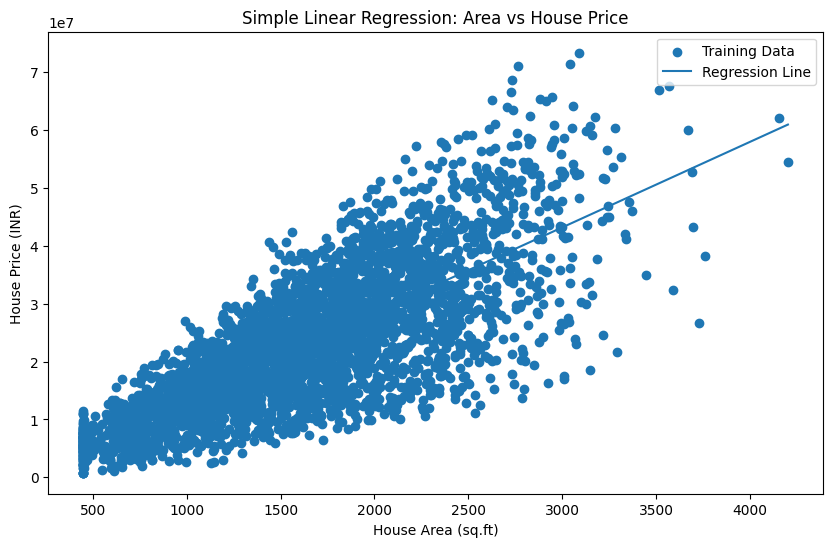

In [10]:
plot_data = X_simple_train.copy()
plot_data['predicted_price'] = lr.predict(X_simple_train)

plot_data = plot_data.sort_values('area_sqft')

plt.figure(figsize=(10, 6))

plt.scatter(
    X_simple_train['area_sqft'],
    y_train,
    label='Training Data'
)

plt.plot(
    plot_data['area_sqft'],
    plot_data['predicted_price'],
    label='Regression Line'
)

plt.xlabel('House Area (sq.ft)')
plt.ylabel('House Price (INR)')
plt.title('Simple Linear Regression: Area vs House Price')
plt.legend()
plt.show()

In [11]:
slope = lr.coef_[0]
intercept = lr.intercept_

print("Slope:", slope)
print("Intercept:", intercept)

Slope: 14788.306111307536
Intercept: -1163519.1764186025


### Interpretation

The slope tells us how much the predicted house price changes for every additional square foot of house area.

The intercept is the theoretical predicted house price when the house area is zero. In a real-world situation, this value does not have a practical interpretation because a house cannot realistically have zero square feet.

Overall, the regression line helps us understand the basic relationship between house area and house price.

## 12. Checking Linear Regression Assumptions

A linear regression model works best when the relationship is reasonably linear and the residuals do not show a clear pattern.

I will check the residuals using plots. Residuals are the differences between the actual house prices and the prices predicted by the model.

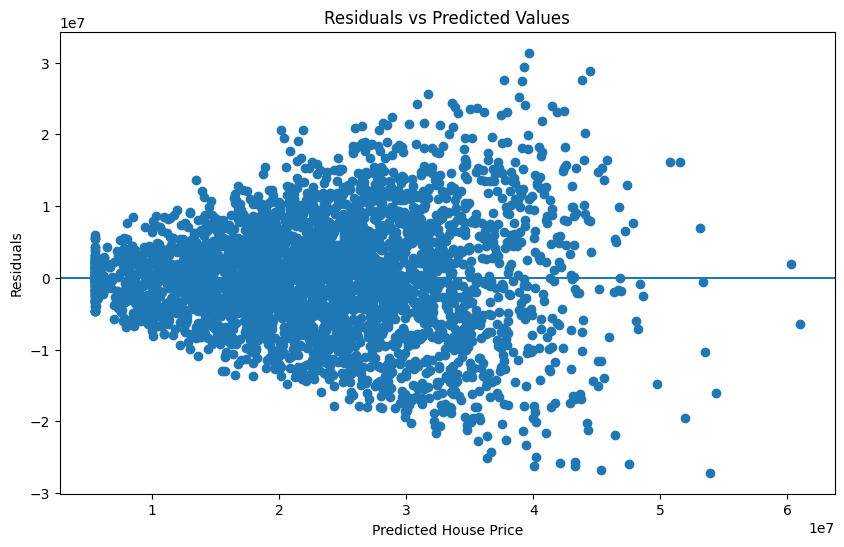

In [12]:
train_predictions = lr.predict(X_simple_train)

residuals = y_train - train_predictions

plt.figure(figsize=(10, 6))

plt.scatter(train_predictions, residuals)

plt.axhline(y=0)

plt.xlabel('Predicted House Price')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')

plt.show()

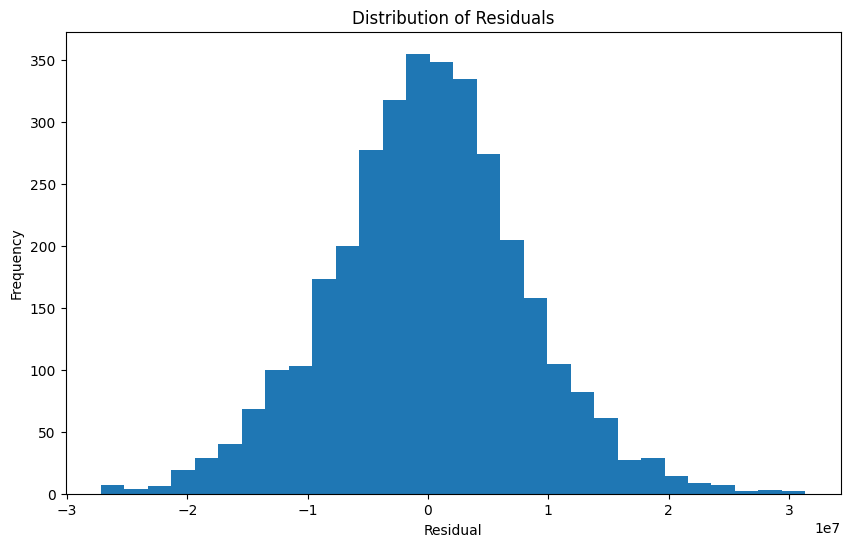

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(residuals, bins=30)

plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')

plt.show()

### Observation

The residuals should ideally be scattered around zero without a clear pattern. This helps assess the linearity and constant-variance assumptions.

The histogram helps us inspect the distribution of the residuals and see whether it is reasonably centered around zero. These plots provide a practical check of the assumptions, although they cannot prove that every assumption is perfectly satisfied.

The independence of observations is treated as a reasonable assumption because each row represents a separate property.

# 📊 Part D: Model Evaluation Metrics

Now I will evaluate the Simple Linear Regression model using:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score
- Adjusted R² Score

In [14]:
mae_simple = mean_absolute_error(y_test, y_pred_simple)

mse_simple = mean_squared_error(y_test, y_pred_simple)

rmse_simple = np.sqrt(mse_simple)

r2_simple = r2_score(y_test, y_pred_simple)

n = len(y_test)
p = 1

adjusted_r2_simple = 1 - (
    ((1 - r2_simple) * (n - 1)) /
    (n - p - 1)
)

print("MAE:", mae_simple)
print("MSE:", mse_simple)
print("RMSE:", rmse_simple)
print("R² Score:", r2_simple)
print("Adjusted R² Score:", adjusted_r2_simple)

MAE: 6294593.696131912
MSE: 66989260021849.47
RMSE: 8184696.696997969
R² Score: 0.5625199587991578
Adjusted R² Score: 0.5619979062440257


## 14. Interpretation of Evaluation Metrics

**MAE:** Shows the average absolute difference between actual and predicted house prices.

**MSE:** Calculates the average squared prediction error. Larger errors receive more penalty because the errors are squared.

**RMSE:** It is the square root of MSE and expresses the prediction error in the same unit as the house price.

**R² Score:** Shows how much of the variation in house prices is explained by the model.

**Adjusted R²:** Similar to R², but it also considers the number of predictors used by the model.

# 📉 Part E: Multiple Linear Regression

Simple Linear Regression uses only house area.

Now I will use all five relevant features together:

- Area
- Bedrooms
- Bathrooms
- Location Score
- Age of Property

This will allow the model to use more information when predicting house prices.

In [15]:
multiple_lr = LinearRegression()

multiple_lr.fit(X_train, y_train)

y_pred_multiple = multiple_lr.predict(X_test)

y_pred_multiple[:10]

array([38097681.51048055, 32211026.21169351, 17587005.93471568,
       31375316.89998732, 22393234.16166412, 29067862.70202291,
        8179420.32955462, 41330564.72046661, 20089381.11371698,
       41876941.70378022])

In [16]:
mae_multiple = mean_absolute_error(y_test, y_pred_multiple)

mse_multiple = mean_squared_error(y_test, y_pred_multiple)

rmse_multiple = np.sqrt(mse_multiple)

r2_multiple = r2_score(y_test, y_pred_multiple)

n = len(y_test)
p = X_test.shape[1]

adjusted_r2_multiple = 1 - (
    ((1 - r2_multiple) * (n - 1)) /
    (n - p - 1)
)

print("MAE:", mae_multiple)
print("MSE:", mse_multiple)
print("RMSE:", rmse_multiple)
print("R² Score:", r2_multiple)
print("Adjusted R² Score:", adjusted_r2_multiple)

MAE: 2641320.376490702
MSE: 12848701729036.898
RMSE: 3584508.575667925
R² Score: 0.9160902723815278
Adjusted R² Score: 0.9155872164605539


In [17]:
coefficients = pd.DataFrame(
    multiple_lr.coef_,
    index=features,
    columns=['Coefficient']
)

coefficients

,Coefficient
area_sqft,1.399138e+04
bedrooms,2.054683e+05
bathrooms,1.922325e+05
location_score,3.385623e+06
age_years,-6.760766e+04


### Coefficient Interpretation

Each coefficient represents the change in predicted house price associated with a one-unit increase in that feature, while keeping the other features constant.

The coefficients therefore help us understand how the different house characteristics contribute to the prediction.

## 16–17. Simple vs Multiple Linear Regression

I will now compare the performance of the Simple Linear Regression model with the Multiple Linear Regression model.

The comparison will help determine whether adding more relevant information improves the prediction.

In [18]:
comparison = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression'
    ],
    'MAE': [
        mae_simple,
        mae_multiple
    ],
    'MSE': [
        mse_simple,
        mse_multiple
    ],
    'RMSE': [
        rmse_simple,
        rmse_multiple
    ],
    'R² Score': [
        r2_simple,
        r2_multiple
    ],
    'Adjusted R²': [
        adjusted_r2_simple,
        adjusted_r2_multiple
    ]
})

comparison

,Model,MAE,MSE,RMSE,R² Score,Adjusted R²
0,Simple Linear Regression,6.294594e+06,6.698926e+13,8.184697e+06,0.56252,0.561998
1,Multiple Linear Regression,2.641320e+06,1.284870e+13,3.584509e+06,0.91609,0.915587


### Observation

The Multiple Linear Regression model performs substantially better than the Simple Linear Regression model.

The Simple Linear Regression model achieved an R² score of approximately **0.563**, while the Multiple Linear Regression model achieved an R² score of approximately **0.916**.

The testing RMSE also decreased from approximately **₹8.18 million** to approximately **₹3.58 million**.

This improvement happens because house price is influenced by several characteristics, not only house area. By including bedrooms, bathrooms, location score, and age of property, the Multiple Linear Regression model can capture more of the information that affects house prices.

Therefore, the additional relevant features significantly improve the model's ability to predict house prices.

# 🔁 Part F: Polynomial Regression

Linear Regression assumes a straight-line relationship between the feature and target.

Polynomial Regression allows the model to capture a curved relationship.

For a simple comparison, I will use **House Area** as the input feature and a polynomial degree of 2.

In [19]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_poly_train = poly.fit_transform(X_simple_train)
X_poly_test = poly.transform(X_simple_test)

poly_lr = LinearRegression()

poly_lr.fit(X_poly_train, y_train)

y_pred_poly = poly_lr.predict(X_poly_test)

y_pred_poly[:10]

array([34385892.28574462, 27442582.20006614, 26884746.34934308,
       21914765.18169425, 31105566.22813011, 24408186.72782708,
       18684160.77396405, 37307586.19334343, 27354560.20870022,
       28145983.85894476])

In [20]:
mae_poly = mean_absolute_error(y_test, y_pred_poly)

mse_poly = mean_squared_error(y_test, y_pred_poly)

rmse_poly = np.sqrt(mse_poly)

r2_poly = r2_score(y_test, y_pred_poly)

n = len(y_test)
p = 2

adjusted_r2_poly = 1 - (
    ((1 - r2_poly) * (n - 1)) /
    (n - p - 1)
)

print("MAE:", mae_poly)
print("MSE:", mse_poly)
print("RMSE:", rmse_poly)
print("R² Score:", r2_poly)
print("Adjusted R² Score:", adjusted_r2_poly)

MAE: 6292394.561281696
MSE: 66962947122198.46
RMSE: 8183089.094113449
R² Score: 0.5626917978136459
Adjusted R² Score: 0.5616468558729377


## 19. Linear vs Polynomial Regression

I will compare the Simple Linear Regression and Polynomial Regression models both visually and numerically.

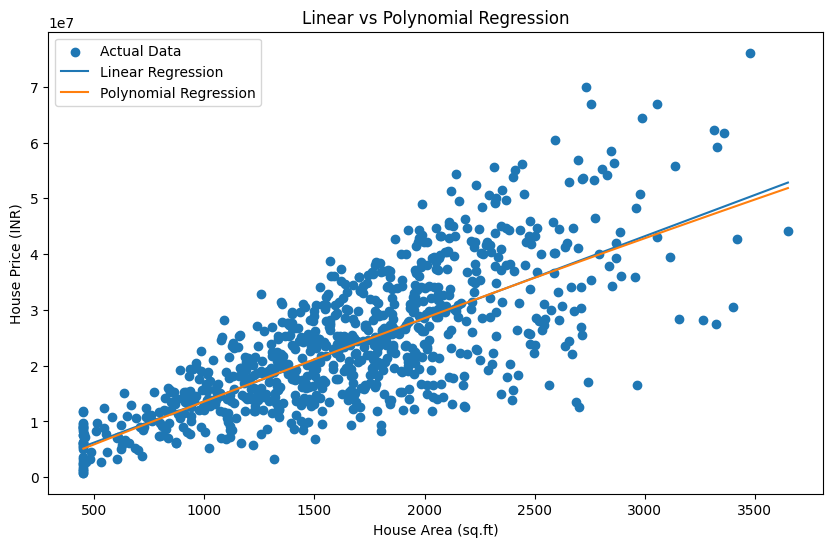

In [21]:
sorted_indices = np.argsort(X_simple_test['area_sqft'].values)

X_test_sorted = X_simple_test.iloc[sorted_indices]

y_pred_simple_sorted = y_pred_simple[sorted_indices]

y_pred_poly_sorted = y_pred_poly[sorted_indices]

plt.figure(figsize=(10, 6))

plt.scatter(
    X_simple_test['area_sqft'],
    y_test,
    label='Actual Data'
)

plt.plot(
    X_test_sorted['area_sqft'],
    y_pred_simple_sorted,
    label='Linear Regression'
)

plt.plot(
    X_test_sorted['area_sqft'],
    y_pred_poly_sorted,
    label='Polynomial Regression'
)

plt.xlabel('House Area (sq.ft)')
plt.ylabel('House Price (INR)')
plt.title('Linear vs Polynomial Regression')
plt.legend()

plt.show()

In [22]:
polynomial_comparison = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Polynomial Regression'
    ],
    'MAE': [
        mae_simple,
        mae_poly
    ],
    'MSE': [
        mse_simple,
        mse_poly
    ],
    'RMSE': [
        rmse_simple,
        rmse_poly
    ],
    'R² Score': [
        r2_simple,
        r2_poly
    ],
    'Adjusted R²': [
        adjusted_r2_simple,
        adjusted_r2_poly
    ]
})

polynomial_comparison

,Model,MAE,MSE,RMSE,R² Score,Adjusted R²
0,Simple Linear Regression,6.294594e+06,6.698926e+13,8.184697e+06,0.562520,0.561998
1,Polynomial Regression,6.292395e+06,6.696295e+13,8.183089e+06,0.562692,0.561647


## 20. Identifying Overfitting and Underfitting

The Polynomial Regression model is more complex than the Simple Linear Regression model because it includes an additional squared term.

If the training error becomes much smaller than the testing error, this can be a sign of overfitting.

If both training and testing errors remain high, the model may be underfitting and may not be complex enough to capture the relationship in the data.

In [23]:
linear_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        lr.predict(X_simple_train)
    )
)

poly_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        poly_lr.predict(X_poly_train)
    )
)

print("Linear Regression Training RMSE:", linear_train_rmse)
print("Linear Regression Testing RMSE:", rmse_simple)

print()

print("Polynomial Regression Training RMSE:", poly_train_rmse)
print("Polynomial Regression Testing RMSE:", rmse_poly)

Linear Regression Training RMSE: 8104428.03525333
Linear Regression Testing RMSE: 8184696.696997969

Polynomial Regression Training RMSE: 8102912.520566771
Polynomial Regression Testing RMSE: 8183089.094113449


### Observation

The Polynomial Regression model has a slightly lower training RMSE and testing RMSE than the Simple Linear Regression model.

However, the improvement is extremely small. The testing RMSE changes from approximately **₹8.185 million** for Simple Linear Regression to approximately **₹8.183 million** for Polynomial Regression.

The R² score also changes only slightly, from approximately **0.563** to approximately **0.563**.

This suggests that adding a degree-2 polynomial term does not provide a meaningful improvement when using house area alone.

There is no strong evidence of overfitting because the training and testing errors are very close to each other. However, the one-feature models still have relatively high prediction error compared with Multiple Linear Regression, suggesting that they are not capturing all the important factors affecting house prices.

Therefore, the main limitation is underfitting caused by using only house area rather than all the relevant features.

# ⚙️ Part G: Gradient Descent Optimization

Gradient Descent is an optimization method used to reduce the error of a machine learning model.

The model starts with initial parameter values and repeatedly updates them in the direction that reduces the cost function.

The basic update idea is:

**Parameter = Parameter − Learning Rate × Gradient**

I will implement three versions:

1. Batch Gradient Descent
2. Stochastic Gradient Descent
3. Mini-Batch Gradient Descent

In [24]:
from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_gd = x_scaler.fit_transform(
    X_train[['area_sqft']]
).ravel()

y_gd = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

print("Gradient Descent dataset prepared.")

Gradient Descent dataset prepared.


## 22. Batch Gradient Descent

Batch Gradient Descent uses the complete training dataset to calculate the gradient before updating the model parameters.

This usually produces a smoother convergence pattern, but each update requires the entire dataset.

In [25]:
def batch_gradient_descent(x, y, learning_rate=0.05, epochs=100):
    
    m = 0
    c = 0
    
    n = len(x)
    cost_history = []
    
    start_time = time.time()
    
    for epoch in range(epochs):
        
        y_predicted = m * x + c
        
        mp = -(2 / n) * np.sum(x * (y - y_predicted))
        cp = -(2 / n) * np.sum(y - y_predicted)
        
        m = m - learning_rate * mp
        c = c - learning_rate * cp
        
        cost = np.mean((y - (m * x + c)) ** 2)
        cost_history.append(cost)
    
    training_time = time.time() - start_time
    
    return m, c, cost_history, training_time

## Running Batch Gradient Descent

In [26]:
m_batch, c_batch, batch_cost, batch_time = batch_gradient_descent(
    X_gd,
    y_gd
)

print("Final slope:", m_batch)
print("Final intercept:", c_batch)
print("Final cost:", batch_cost[-1])
print("Training time:", batch_time, "seconds")

Final slope: 0.7564899746486269
Final intercept: 8.30552557945772e-17
Final cost: 0.4276925164889216
Training time: 0.007192373275756836 seconds


## 23. Stochastic Gradient Descent

Stochastic Gradient Descent updates the model parameters after processing one data point at a time.

Unlike Batch Gradient Descent, it does not wait to process the complete dataset before making an update.

Because of this, its convergence can be more noisy, but it can make frequent updates.

In [27]:
def stochastic_gradient_descent(
    x,
    y,
    learning_rate=0.01,
    epochs=100
):
    
    m = 0
    c = 0
    
    n = len(x)
    cost_history = []
    
    rng = np.random.default_rng(42)
    
    start_time = time.time()
    
    for epoch in range(epochs):
        
        data_indices = rng.permutation(n)
        
        for i in data_indices:
            
            x_i = x[i]
            y_i = y[i]
            
            y_predicted = m * x_i + c
            
            mp = -2 * x_i * (y_i - y_predicted)
            cp = -2 * (y_i - y_predicted)
            
            m = m - learning_rate * mp
            c = c - learning_rate * cp
        
        y_predicted_all = m * x + c
        
        cost = np.mean(
            (y - y_predicted_all) ** 2
        )
        
        cost_history.append(cost)
    
    training_time = time.time() - start_time
    
    return m, c, cost_history, training_time

## Running Stochastic Gradient Descent

In [28]:
m_sgd, c_sgd, sgd_cost, sgd_time = stochastic_gradient_descent(
    X_gd,
    y_gd
)

print("Final slope:", m_sgd)
print("Final intercept:", c_sgd)
print("Final cost:", sgd_cost[-1])
print("Training time:", sgd_time, "seconds")

Final slope: 0.7692551750724712
Final intercept: -0.007460906897287034
Final cost: 0.42791061895551374
Training time: 0.44492459297180176 seconds


## 24. Mini-Batch Gradient Descent

Mini-Batch Gradient Descent divides the training data into smaller groups called mini-batches.

Instead of using the entire dataset like Batch Gradient Descent or one data point like SGD, it updates the model using a small group of observations at a time.

In [29]:
def mini_batch_gradient_descent(
    x,
    y,
    learning_rate=0.03,
    epochs=100,
    batch_size=32
):
    
    m = 0
    c = 0
    
    n = len(x)
    cost_history = []
    
    rng = np.random.default_rng(42)
    
    start_time = time.time()
    
    for epoch in range(epochs):
        
        data_indices = rng.permutation(n)
        
        for i in range(0, n, batch_size):
            
            batch_indices = data_indices[
                i:i + batch_size
            ]
            
            x_batch = x[batch_indices]
            y_batch = y[batch_indices]
            
            n_batch = len(x_batch)
            
            y_predicted = m * x_batch + c
            
            mp = -(2 / n_batch) * np.sum(
                x_batch * (y_batch - y_predicted)
            )
            
            cp = -(2 / n_batch) * np.sum(
                y_batch - y_predicted
            )
            
            m = m - learning_rate * mp
            c = c - learning_rate * cp
        
        y_predicted_all = m * x + c
        
        cost = np.mean(
            (y - y_predicted_all) ** 2
        )
        
        cost_history.append(cost)
    
    training_time = time.time() - start_time
    
    return m, c, cost_history, training_time

## Running Mini-Batch Gradient Descent

In [30]:
m_mini, c_mini, mini_cost, mini_time = mini_batch_gradient_descent(
    X_gd,
    y_gd
)

print("Final slope:", m_mini)
print("Final intercept:", c_mini)
print("Final cost:", mini_cost[-1])
print("Training time:", mini_time, "seconds")

Final slope: 0.7634884073437783
Final intercept: -0.006328493729803569
Final cost: 0.4277812631294653
Training time: 0.2997152805328369 seconds


## 25. Comparing Convergence Behaviour and Training Time

Now I will compare the three gradient descent methods.

The cost history shows how the error changes during training, while the training time shows how long each method took to complete.

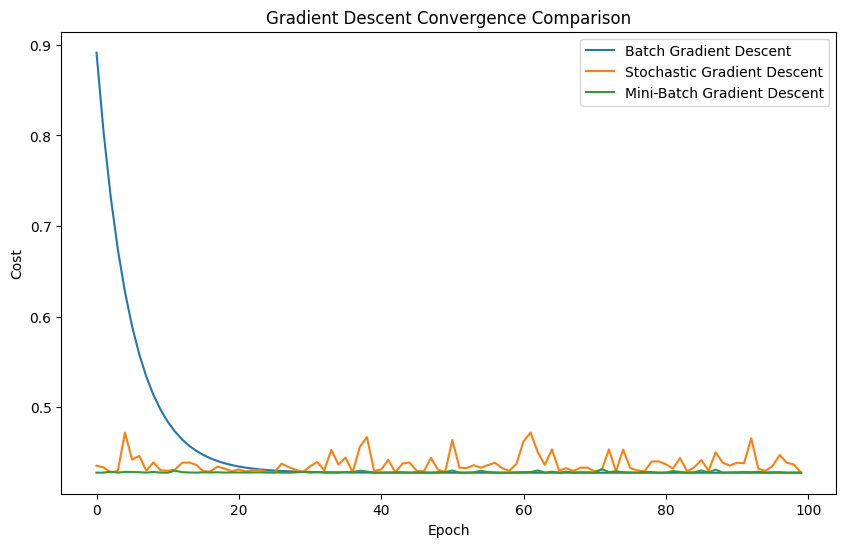

In [31]:
plt.figure(figsize=(10, 6))

plt.plot(batch_cost, label='Batch Gradient Descent')
plt.plot(sgd_cost, label='Stochastic Gradient Descent')
plt.plot(mini_cost, label='Mini-Batch Gradient Descent')

plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Gradient Descent Convergence Comparison')
plt.legend()

plt.show()

In [32]:
gradient_descent_comparison = pd.DataFrame({
    'Method': [
        'Batch Gradient Descent',
        'Stochastic Gradient Descent',
        'Mini-Batch Gradient Descent'
    ],
    'Final Cost': [
        batch_cost[-1],
        sgd_cost[-1],
        mini_cost[-1]
    ],
    'Training Time (seconds)': [
        batch_time,
        sgd_time,
        mini_time
    ]
})

gradient_descent_comparison

,Method,Final Cost,Training Time (seconds)
0,Batch Gradient Descent,0.427693,0.007192
1,Stochastic Gradient Descent,0.427911,0.444925
2,Mini-Batch Gradient Descent,0.427781,0.299715


### Observation

Batch Gradient Descent uses the complete training dataset for each parameter update, so its convergence is generally smoother.

Stochastic Gradient Descent updates the parameters using one observation at a time. Because of this, its convergence can be more variable.

Mini-Batch Gradient Descent updates the parameters using a small group of observations, providing a balance between Batch Gradient Descent and Stochastic Gradient Descent.

The training-time results depend on the computer and the current run, so the timing table should be used to compare the three methods for this experiment.

## 26. Bias and Variance Analysis

To compare bias and variance, I will use the difference between training and testing error as a practical diagnostic.

A model with high training error may have high bias because it is too simple to capture the underlying relationship.

A large difference between training and testing error can indicate higher variance because the model performs much better on training data than on unseen data.

This is a practical diagnostic rather than a formal mathematical bias-variance decomposition.

In [33]:
simple_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        lr.predict(X_simple_train)
    )
)

multiple_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        multiple_lr.predict(X_train)
    )
)

poly_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        poly_lr.predict(X_poly_train)
    )
)

model_diagnostics = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression'
    ],
    'Training RMSE': [
        simple_train_rmse,
        multiple_train_rmse,
        poly_train_rmse
    ],
    'Testing RMSE': [
        rmse_simple,
        rmse_multiple,
        rmse_poly
    ]
})

model_diagnostics['Generalization Gap'] = (
    model_diagnostics['Testing RMSE']
    - model_diagnostics['Training RMSE']
)

model_diagnostics['Relative Gap (%)'] = (
    model_diagnostics['Generalization Gap']
    / model_diagnostics['Training RMSE']
) * 100

model_diagnostics

,Model,Training RMSE,Testing RMSE,Generalization Gap,Relative Gap (%)
0,Simple Linear Regression,8.104428e+06,8.184697e+06,80268.661745,0.990430
1,Multiple Linear Regression,3.455798e+06,3.584509e+06,128710.995271,3.724495
2,Polynomial Regression,8.102913e+06,8.183089e+06,80176.573547,0.989478


# 📐 Part H: Bias–Variance & Model Diagnostics

Model complexity affects how well a model learns the underlying relationship.

A simple model can have high bias because it may not capture enough information. A very complex model can have high variance because it may become too sensitive to the training data.

I will compare the training and testing errors of the Simple Linear Regression, Polynomial Regression, and Multiple Linear Regression models.

## 27. Effect of Model Complexity on Prediction Error

The Simple Linear Regression model is the simplest model because it uses only house area.

Polynomial Regression increases the complexity of the relationship by adding a squared term, but in this dataset the improvement is extremely small.

Multiple Linear Regression increases the amount of information available to the model by using five relevant features. This significantly reduces the prediction error.

This shows that increasing complexity is useful when the added information is relevant. However, unnecessary complexity can increase variance and may lead to overfitting.

## 28. Best Balance Between Bias and Variance

Based on the model diagnostics, Multiple Linear Regression provides the best balance for this dataset.

It has a much lower training RMSE and testing RMSE than the Simple and Polynomial Regression models. Its testing RMSE is approximately **₹3.58 million**, compared with approximately **₹8.18 million** for the other two models.

Although Multiple Linear Regression has a slightly larger training-testing gap, the gap is still relatively small compared with its overall improvement in prediction accuracy.

The Polynomial Regression model has a very small training-testing gap, but its prediction error remains high. This suggests that it is stable but still too limited because it uses only house area.

Therefore, Multiple Linear Regression provides the most useful balance between model complexity, prediction accuracy, bias, and variance for this dataset.

In [34]:
model_diagnostics[
    [
        'Model',
        'Training RMSE',
        'Testing RMSE',
        'Generalization Gap',
        'Relative Gap (%)'
    ]
]

,Model,Training RMSE,Testing RMSE,Generalization Gap,Relative Gap (%)
0,Simple Linear Regression,8.104428e+06,8.184697e+06,80268.661745,0.990430
1,Multiple Linear Regression,3.455798e+06,3.584509e+06,128710.995271,3.724495
2,Polynomial Regression,8.102913e+06,8.183089e+06,80176.573547,0.989478


# 🧾 Part I: Final Analysis & Reporting

The final step is to bring together the results from all the models and understand what they mean from a practical business perspective.

In [35]:
final_results = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression'
    ],
    'MAE': [
        mae_simple,
        mae_multiple,
        mae_poly
    ],
    'MSE': [
        mse_simple,
        mse_multiple,
        mse_poly
    ],
    'RMSE': [
        rmse_simple,
        rmse_multiple,
        rmse_poly
    ],
    'R² Score': [
        r2_simple,
        r2_multiple,
        r2_poly
    ],
    'Adjusted R²': [
        adjusted_r2_simple,
        adjusted_r2_multiple,
        adjusted_r2_poly
    ]
})

final_results

,Model,MAE,MSE,RMSE,R² Score,Adjusted R²
0,Simple Linear Regression,6.294594e+06,6.698926e+13,8.184697e+06,0.562520,0.561998
1,Multiple Linear Regression,2.641320e+06,1.284870e+13,3.584509e+06,0.916090,0.915587
2,Polynomial Regression,6.292395e+06,6.696295e+13,8.183089e+06,0.562692,0.561647


## 29. Final Findings

### Best-Performing Model

The **Multiple Linear Regression model** is the best-performing model in this project.

It achieved a testing RMSE of approximately **₹3.58 million** and an R² score of approximately **0.916**.

In comparison, Simple Linear Regression achieved a testing RMSE of approximately **₹8.18 million** and an R² score of approximately **0.563**.

This shows that using multiple relevant house characteristics provides a much better prediction of house prices than using house area alone.

### Impact of Gradient Descent Optimization

The Gradient Descent experiments demonstrated how model parameters can be optimized by repeatedly reducing the cost function.

The convergence plot shows how the cost changes across epochs for Batch, Stochastic, and Mini-Batch Gradient Descent. The timing table also shows the training time of each method for this particular run.

Batch Gradient Descent uses the complete training set for each update, Stochastic Gradient Descent updates after individual observations, and Mini-Batch Gradient Descent updates using small groups of observations.

### Evidence of Overfitting and Underfitting

The Simple and Polynomial Regression models have relatively high training and testing errors, indicating that they do not capture all the information required to predict house prices accurately.

The Polynomial Regression model only provides a very small improvement over Simple Linear Regression, so adding a degree-2 polynomial term does not solve the main limitation.

There is no strong evidence of severe overfitting because the training and testing errors are relatively close. The main limitation is underfitting in the one-feature models because they use only house area while house prices depend on several relevant characteristics.

### Practical Business Interpretation

For a real estate analytics company, using several relevant property characteristics provides a much more useful prediction system than relying only on house area.

The Multiple Linear Regression model uses area, bedrooms, bathrooms, location score, and property age together to estimate house prices.

This could support property valuation, pricing analysis, and initial decision-making when evaluating properties.

## Final Model Performance Comparison

The following chart compares the testing RMSE of the three regression models.

A lower RMSE indicates lower prediction error.

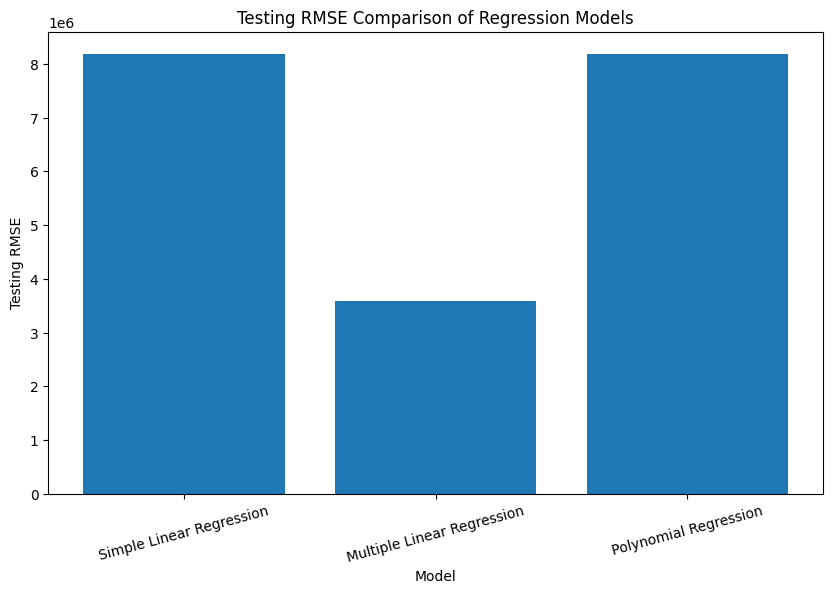

In [36]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_results['Model'],
    final_results['RMSE']
)

plt.ylabel('Testing RMSE')
plt.xlabel('Model')
plt.title('Testing RMSE Comparison of Regression Models')

plt.xticks(rotation=15)

plt.show()

# 🏁 Final Conclusion

In this project, I built and evaluated several supervised learning regression models for predicting house prices.

I started with Simple Linear Regression using house area as the only feature. The model achieved an R² score of approximately **0.563**.

I then implemented Multiple Linear Regression using house area, bedrooms, bathrooms, location score, and age of property. This model achieved an R² score of approximately **0.916**, with a testing RMSE of approximately **₹3.58 million**.

Polynomial Regression was also tested using degree 2. It produced only a very small improvement over Simple Linear Regression, showing that increasing complexity through a polynomial term did not provide a significant benefit when only house area was used.

I also implemented Batch Gradient Descent, Stochastic Gradient Descent, and Mini-Batch Gradient Descent from scratch. All three methods successfully reduced the cost function, while their convergence behaviour and training times were different.

The model diagnostics showed that Multiple Linear Regression provides the best overall balance between prediction accuracy, model complexity, bias, and variance for this dataset.

From a business perspective, the results demonstrate that house prices are better predicted by considering multiple relevant property characteristics rather than relying on a single feature.

Overall, this project helped me understand how supervised learning regression models can be implemented, evaluated, compared, and interpreted for a real-world prediction problem.